# HMDA 2024 – B17 - Predictive (Group 3)

**Task:** B17 - Predictive | Section 6 – Predictive Extension  
**Models:** Logistic Regression and Random Forest  
**Input:** `B06_analytic.parquet`  
**Notebook status:** Step 5 structural and static-code review completed. Previous cached execution outputs do not establish a clean Restart & Run All; full HMDA-data execution and model diagnostics require validation in the project environment.

## Research scope

This notebook predicts whether an application is denied using pre-decision application characteristics. It is an analytical extension, not an underwriting system and not a causal analysis.

The modeling sample follows the Group 3 proposal:
- `action_taken = 1` (Originated) → `is_denied = 0`
- `action_taken = 2` (Approved but not accepted) → `is_denied = 0`
- `action_taken = 3` (Denied) → `is_denied = 1`

The approved sampling design is **200,000 rows**, stratified by the original `action_taken` values `{1, 2, 3}`, without replacement, using sampling seed `42`.

## Project conventions

This notebook follows `Coding and documenting conventions.md` (v2): English Markdown and code, one Markdown cell immediately before each code cell, Input–Process–Output explanations, short code cells, traceable outputs, and no manually typed analytical results.

**Decision scope:** Sampling settings and baseline implementation defaults in P0.1 were approved by the Human. Those baseline defaults are not stated requirements of the proposal. Changing them, especially model hyperparameters, requires a documented new decision.



## P0. Configuration and reproducibility

**Input:** B06 analytic dataset stored in the project's `input/` directory and Human-approved baseline implementation choices.

**Process:** Import libraries; configure the task code, project-relative input/output paths, random seeds, sampling settings, and model defaults in one initial configuration cell. The notebook must be executed from the `B17 - Predictive/` project directory.

**Output:** An initialized `B17` output directory, configuration values, and a displayed decision register.

In [4]:

# ============================================================
# P0. CONFIGURATION AND REPRODUCIBILITY
# ============================================================

# Step 1: Import dependencies
from pathlib import Path
import time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, precision_recall_curve, auc,
    average_precision_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay
)

# Step 2: Configure project directories
TASK_CODE = "B17"

NOTEBOOK_DIR = Path.cwd().resolve()

if NOTEBOOK_DIR.name != "B17 - Predictive":
    raise RuntimeError(
        "Run the notebook from the 'B17 - Predictive' folder."
    )

PROJECT_DIR = NOTEBOOK_DIR.parent
OUTPUT_DIR = NOTEBOOK_DIR / "output"

# Step 2A: Automatically locate B06 analytical Parquet
INPUT_DIR = NOTEBOOK_DIR / "input"
INPUT_PATH = INPUT_DIR / "B06_analytic.parquet"

if not INPUT_PATH.is_file():

    matches = sorted(
        p for p in PROJECT_DIR.glob(
            "B06*/output/B06_analytic.parquet"
        )
        if p.is_file()
    )

    if len(matches) == 1:
        INPUT_PATH = matches[0].resolve()
        INPUT_DIR = INPUT_PATH.parent

    elif len(matches) == 0:
        raise FileNotFoundError(
            "Cannot find B06_analytic.parquet.\n"
            "Checked B17/input and B06*/output.\n"
            "Please verify that B06 exported the file."
        )

    else:
        raise RuntimeError(
            f"Multiple B06 analytical files found: {matches}"
        )

SAMPLE_PATH = OUTPUT_DIR / f"{TASK_CODE}_modeling_sample.parquet"

# Step 3: Configure approved sampling settings
SAMPLE_SIZE = 200_000
SAMPLING_SEED = 42
BATCH_SIZE = 250_000
ACTION_CODES = ("1", "2", "3")

# Step 4: Configure baseline implementation settings
TEST_SIZE = 0.20
SPLIT_SEED = 42

NUMERIC_IMPUTER_STRATEGY = "median"
CATEGORICAL_MISSING_TOKEN = "__MISSING__"

CLASSIFICATION_THRESHOLD = 0.50
CLASS_WEIGHT = None

LR_PARAMS = {
    "solver": "lbfgs",
    "max_iter": 3000,
    "class_weight": CLASS_WEIGHT,
    "random_state": 42,
    "n_jobs": -1
}

RF_PARAMS = {
    "n_estimators": 100,
    "max_depth": 16,
    "min_samples_leaf": 5,
    "max_features": "sqrt",
    "class_weight": CLASS_WEIGHT,
    "random_state": 42,
    "n_jobs": -1
}

APPROVE_PROVISIONAL_SETTINGS = True

# Step 5: Initialize output directory
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Step 6: Display configuration and decision register
decision_register = pd.DataFrame([
    ["Train/evaluation split", "Stratified 80/20",
     "Human-approved baseline"],
    ["Numeric missing values", "Training-set median",
     "Human-approved baseline"],
    ["Categorical missing values", CATEGORICAL_MISSING_TOKEN,
     "Human-approved baseline"],
    ["Classification threshold", CLASSIFICATION_THRESHOLD,
     "Human-approved baseline"],
    ["Class weighting", str(CLASS_WEIGHT),
     "Human-approved baseline"],
    ["LR and RF hyperparameters", "LR_PARAMS / RF_PARAMS",
     "Human-approved baseline"],
    ["Cross-validation/tuning", "Excluded from this baseline",
     "Not required by proposal"]
], columns=["Decision", "Current setting", "Status"])

print(f"Project directory: {NOTEBOOK_DIR}")
print(f"Input directory: {INPUT_DIR}")
print(f"Input file: {INPUT_PATH}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Sample size: {SAMPLE_SIZE:,}")
print(f"Sampling seed: {SAMPLING_SEED}")

display(decision_register)


Project directory: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive
Input directory: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B06 - Clean\output
Input file: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B06 - Clean\output\B06_analytic.parquet
Output directory: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output
Sample size: 200,000
Sampling seed: 42


,Decision,Current setting,Status
0,Train/evaluation split,Stratified 80/20,Human-approved baseline
1,Numeric missing values,Training-set median,Human-approved baseline
2,Categorical missing values,__MISSING__,Human-approved baseline
3,Classification threshold,0.5,Human-approved baseline
4,Class weighting,None,Human-approved baseline
5,LR and RF hyperparameters,LR_PARAMS / RF_PARAMS,Human-approved baseline
6,Cross-validation/tuning,Excluded from this baseline,Not required by proposal


### P0.1. Decision register and baseline scope

**Input:** Human approval of the provisional implementation settings and the Group 3 proposal.  
**Process:** Review the decision register displayed by P0. Its statuses distinguish Human-approved *baseline implementation choices* from requirements explicitly stated by the proposal. The setting `APPROVE_PROVISIONAL_SETTINGS = True` remains named as before for compatibility with the existing P5 guard.  
**Output:** A documented and visible set of baseline assumptions; subsequent sections reuse the P0 configuration without redeclaring constants.

**[Verified: Human decision]** The sampling size/seed and the baseline defaults were approved for this run. **[Hypothesis]** These technical defaults are reasonable starting points; their predictive performance and convergence still require empirical validation. Changes to hyperparameters or preprocessing require a separately recorded decision.

**[CHANGE: Step 2]** Logistic Regression uses `lbfgs` with up to `3000` iterations instead of `saga` with `1000` iterations because the previous run reported a convergence warning. This is a revised modeling setting, not a proposal requirement; model metrics may change. **[Human decision required]** Confirm the solver/iteration change for the final decision log after reviewing the new run.


## P1. Input and schema audit

**Input:** `B06_analytic.parquet`.  
**Process:** Verify the file, inspect Parquet metadata and confirm that all proposal-specified predictor columns are present. Only schema metadata is read at this stage.  
**Output:** Input dimensions, file size, row-group count, and a schema table.

In [5]:
# Step 1: Verify the input file
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Input file not found: {INPUT_PATH}")

parquet_file = pq.ParquetFile(INPUT_PATH)
metadata = parquet_file.metadata
print(f"Rows: {metadata.num_rows:,}")
print(f"Row groups: {metadata.num_row_groups:,}")
print(f"File size: {INPUT_PATH.stat().st_size / 1024**3:.2f} GB")

# Step 2: Inspect the Arrow schema
schema_table = pd.DataFrame({
    "column": parquet_file.schema_arrow.names,
    "arrow_type": [str(field.type) for field in parquet_file.schema_arrow]
})
display(schema_table)

Rows: 8,136,664
Row groups: 50
File size: 0.52 GB


,column,arrow_type
0,activity_year,int64
1,lei,string
2,derived_msa_md,string
3,state_code,string
4,county_code,string
...,...,...
164,dup_group_size,int32
165,flag_dup_extra,bool
166,in_s0,bool
167,in_s5_all,bool


### P1.1. Required-column validation

**Input:** Parquet schema from P1.  
**Process:** Check the exact columns needed for the proposal's core predictors and target construction.  
**Output:** A validation result that stops execution if a required column is absent.

In [6]:
# Step 1: Map proposal concepts to observed columns
NUMERIC_FEATURES = [
    "income", "loan_amount", "combined_loan_to_value_ratio"
]
CATEGORICAL_FEATURES = [
    "debt_to_income_ratio", "loan_type", "loan_purpose",
    "lien_status", "occupancy_type"
]
PREDICTOR_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
REQUIRED_COLUMNS = ["action_taken"] + PREDICTOR_COLUMNS

# Step 2: Validate the schema
missing_columns = [c for c in REQUIRED_COLUMNS if c not in parquet_file.schema_arrow.names]
if missing_columns:
    raise ValueError(f"Required columns missing from input: {missing_columns}")

print("All required columns are present.")
print("Numeric predictors:", NUMERIC_FEATURES)
print("Categorical predictors:", CATEGORICAL_FEATURES)

All required columns are present.
Numeric predictors: ['income', 'loan_amount', 'combined_loan_to_value_ratio']
Categorical predictors: ['debt_to_income_ratio', 'loan_type', 'loan_purpose', 'lien_status', 'occupancy_type']


## P2. Stratified sampling and target construction

### P2.1. Count eligible outcomes

**Input:** The `action_taken` column only.  
**Process:** Stream through the Parquet file in batches and count values `1`, `2`, and `3` without loading the full dataset into memory.  
**Output:** Exact eligible population counts and a check that the approved sample size is feasible.

In [7]:
# Step 1: Count the three eligible action_taken values
action_counts = {code: 0 for code in ACTION_CODES}
for batch in parquet_file.iter_batches(
    batch_size=BATCH_SIZE, columns=["action_taken"]
):
    values = batch.column(0).to_pandas().astype("string").str.strip()
    batch_counts = values.value_counts(dropna=True)
    for action_code in ACTION_CODES:
        action_counts[action_code] += int(batch_counts.get(action_code, 0))

eligible_population = sum(action_counts.values())
if eligible_population < SAMPLE_SIZE:
    raise ValueError("Eligible population is smaller than the approved sample size.")

action_count_table = pd.DataFrame([
    {"action_taken": code, "population_count": action_counts[code]}
    for code in ACTION_CODES
])
display(action_count_table)
print(f"Eligible population: {eligible_population:,}")

,action_taken,population_count
0,1,5793597
1,2,339791
2,3,2003276


Eligible population: 8,136,664


### P2.2. Allocate the sample proportionally

**Input:** Exact population counts from P2.1.  
**Process:** Calculate proportional quotas and use the largest-remainder method so the integer allocations sum exactly to 200,000.  
**Output:** Reproducible sample allocation by original `action_taken` value.

In [8]:
# Step 1: Allocate integer sample counts using largest remainders
def allocate_sample_counts(counts, sample_size):
    """Allocate a fixed sample proportionally across strata."""
    total = sum(counts.values())
    quotas = {k: sample_size * v / total for k, v in counts.items()}
    allocation = {k: int(np.floor(v)) for k, v in quotas.items()}
    remaining = sample_size - sum(allocation.values())
    order = sorted(counts, key=lambda k: quotas[k] - allocation[k], reverse=True)
    for key in order[:remaining]:
        allocation[key] += 1
    return allocation

sample_allocation = allocate_sample_counts(action_counts, SAMPLE_SIZE)
allocation_table = pd.DataFrame([
    {
        "action_taken": k,
        "population_count": action_counts[k],
        "population_share": action_counts[k] / eligible_population,
        "sample_count": sample_allocation[k]
    }
    for k in ACTION_CODES
])
assert sum(sample_allocation.values()) == SAMPLE_SIZE
display(allocation_table)

,action_taken,population_count,population_share,sample_count
0,1,5793597,0.712036,142407
1,2,339791,0.041760,8352
2,3,2003276,0.246204,49241


### P2.3. Streaming reservoir update

**Input:** The current retained candidates and new candidates from one Parquet batch.  
**Process:** Keep the rows with the smallest independent random priorities within each stratum. Retaining the lowest `k` priorities across the full scan produces a uniform sample without replacement for that stratum.  
**Output:** An updated bounded-size reservoir; memory use is limited by the requested sample size.

In [9]:
# Step 1: Update one stratum's retained sample
def update_reservoir(current, candidates, keep_n):
    """Retain the keep_n smallest random priorities without replacement."""
    combined = pd.concat([current, candidates], ignore_index=True)
    if len(combined) > keep_n:
        priorities = combined["_sample_priority"].to_numpy()
        selected = np.argpartition(priorities, keep_n - 1)[:keep_n]
        combined = combined.iloc[selected].reset_index(drop=True)
    return combined

### P2.4. Run the stratified sample

**Input:** Required predictor columns, `action_taken`, approved allocations, and sampling seed `42`.  
**Process:** Scan only the nine required source columns in batches. Generate random priorities and retain exactly the allocated number of rows from each action stratum. A source-row identifier is retained for traceability, not used as a predictor.  
**Output:** Exactly 200,000 sampled applications, selected without replacement.

In [10]:
# Step 1: Stream the required columns and retain random-priority reservoirs
SAMPLE_COLUMNS = ["action_taken"] + PREDICTOR_COLUMNS
rng = np.random.default_rng(SAMPLING_SEED)
reservoirs = {k: pd.DataFrame() for k in ACTION_CODES}
source_offset = 0

for batch in parquet_file.iter_batches(
    batch_size=BATCH_SIZE, columns=SAMPLE_COLUMNS
):
    batch_df = batch.to_pandas()
    actions = batch_df["action_taken"].astype("string").str.strip()
    positions = np.arange(source_offset, source_offset + len(batch_df))
    for action_code in ACTION_CODES:
        mask = actions.eq(action_code).fillna(False).to_numpy(dtype=bool)
        if mask.any():
            candidates = batch_df.loc[mask, SAMPLE_COLUMNS].copy()
            candidates["_source_row_id"] = positions[mask]
            candidates["_sample_priority"] = rng.random(mask.sum())
            reservoirs[action_code] = update_reservoir(
                reservoirs[action_code], candidates, sample_allocation[action_code]
            )
    source_offset += len(batch_df)

# Step 2: Combine and validate the sampled strata
for action_code in ACTION_CODES:
    assert len(reservoirs[action_code]) == sample_allocation[action_code]
sample_df = pd.concat(reservoirs.values(), ignore_index=True)
sample_df = sample_df.sort_values("_source_row_id").reset_index(drop=True)
sample_df = sample_df.drop(columns="_sample_priority")
assert len(sample_df) == SAMPLE_SIZE
assert sample_df["_source_row_id"].is_unique
print(f"Sampled rows: {len(sample_df):,}")

Sampled rows: 200,000


### P2.5. Create the target and save the sample

**Input:** The sampled rows and original `action_taken`.  
**Process:** Map action `3` to denied (`1`) and actions `1` and `2` to not denied (`0`). Reconcile counts, then save the modeling sample and allocation table.  
**Output:** A traceable Parquet modeling sample and sample-allocation CSV, with paths, file sizes, and row/column counts printed for both artifacts.

**[ADD: Step 4]** Report export metadata for the allocation CSV as well as the modeling-sample Parquet; target construction and sample selection remain unchanged.

In [11]:
# Step 1: Construct the binary target
sample_df["action_taken"] = sample_df["action_taken"].astype("string").str.strip()
sample_df["is_denied"] = (sample_df["action_taken"] == "3").astype("int8")

target_counts = sample_df["is_denied"].value_counts().sort_index()
assert set(sample_df["action_taken"].dropna().unique()).issubset(ACTION_CODES)
assert int(target_counts.sum()) == SAMPLE_SIZE
assert (sample_df.loc[sample_df["action_taken"] == "3", "is_denied"] == 1).all()
assert (sample_df.loc[sample_df["action_taken"].isin(["1", "2"]), "is_denied"] == 0).all()

# Step 2: Save the sampled modeling data
sample_df.to_parquet(SAMPLE_PATH, index=False, compression="snappy")
allocation_path = OUTPUT_DIR / f"{TASK_CODE}_sample_allocation.csv"
allocation_table.to_csv(allocation_path, index=False)

# Step 3: Report metadata for both saved artifacts
for path, table in [(SAMPLE_PATH, sample_df), (allocation_path, allocation_table)]:
    print(f"Saved: {path} | {path.stat().st_size:,} bytes | "
          f"{table.shape[0]:,} rows x {table.shape[1]} columns")

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_modeling_sample.parquet | 2,511,564 bytes | 200,000 rows x 11 columns
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_sample_allocation.csv | 170 bytes | 3 rows x 4 columns


## P3. Predictor and leakage audit

**Input:** The sampled modeling dataset.  
**Process:** Load the saved sample, verify the approved predictor allowlist, and explicitly exclude target, original outcome, source identifier, demographics, and denial-reason fields from `X`.  
**Output:** Predictor audit table and a leakage validation result.

In [12]:
# Step 1: Load the saved sample and define explicit exclusions
model_df = pd.read_parquet(SAMPLE_PATH)
FORBIDDEN_PREDICTORS = {
    "action_taken", "is_denied", "_source_row_id",
    "denial_reason_1", "denial_reason_2",
    "denial_reason_3", "denial_reason_4",
    "derived_race", "derived_ethnicity", "derived_sex"
}
assert not set(PREDICTOR_COLUMNS).intersection(FORBIDDEN_PREDICTORS)
assert all(c in model_df.columns for c in PREDICTOR_COLUMNS)

# Step 2: Build the predictor audit
predictor_audit = pd.DataFrame({
    "predictor": PREDICTOR_COLUMNS,
    "group": ["Numeric"] * len(NUMERIC_FEATURES) + ["Categorical"] * len(CATEGORICAL_FEATURES),
    "dtype": [str(model_df[c].dtype) for c in PREDICTOR_COLUMNS],
    "missing_count": [int(model_df[c].isna().sum()) for c in PREDICTOR_COLUMNS],
    "missing_pct": [model_df[c].isna().mean() * 100 for c in PREDICTOR_COLUMNS],
    "status": "Included – proposal core predictor"
})
display(predictor_audit)
print("Excluded from predictors:", sorted(FORBIDDEN_PREDICTORS))

,predictor,group,dtype,missing_count,missing_pct,status
0,income,Numeric,float64,7371,3.6855,Included – proposal core predictor
1,loan_amount,Numeric,float64,0,0.0000,Included – proposal core predictor
2,combined_loan_to_value_ratio,Numeric,float64,20743,10.3715,Included – proposal core predictor
3,debt_to_income_ratio,Categorical,string,15415,7.7075,Included – proposal core predictor
4,loan_type,Categorical,string,0,0.0000,Included – proposal core predictor
5,loan_purpose,Categorical,string,0,0.0000,Included – proposal core predictor
6,lien_status,Categorical,string,0,0.0000,Included – proposal core predictor
7,occupancy_type,Categorical,string,0,0.0000,Included – proposal core predictor


Excluded from predictors: ['_source_row_id', 'action_taken', 'denial_reason_1', 'denial_reason_2', 'denial_reason_3', 'denial_reason_4', 'derived_ethnicity', 'derived_race', 'derived_sex', 'is_denied']


### P3.1. Verify target and predictor integrity

**Input:** Sampled target and predictor columns.  
**Process:** Confirm target values, check numeric predictor types, and ensure no denial-reason or target columns enter the predictor list.  
**Output:** Integrity checks before preprocessing.

In [13]:
# Step 1: Validate target and predictor types
assert model_df["is_denied"].isin([0, 1]).all()
assert pd.api.types.is_numeric_dtype(model_df["income"])
assert pd.api.types.is_numeric_dtype(model_df["loan_amount"])
assert pd.api.types.is_numeric_dtype(model_df["combined_loan_to_value_ratio"])

# Step 2: Check source outcome and target reconciliation
target_check = pd.crosstab(model_df["action_taken"], model_df["is_denied"])
display(target_check)
assert target_check.loc["1", 0] == sample_allocation["1"]
assert target_check.loc["2", 0] == sample_allocation["2"]
assert target_check.loc["3", 1] == sample_allocation["3"]
print("Target and predictor integrity checks passed.")

is_denied,0,1
action_taken,,
1,142407,0
2,8352,0
3,0,49241


Target and predictor integrity checks passed.


## P4. Missing-value audit and preprocessing design

**Input:** Approved predictors in the 200,000-row sample.  
**Process:** Report missingness and inspect common literal special tokens in categorical columns. Do not convert `NA`, `Exempt`, or other text tokens to zero or silently reinterpret them.  
**Output:** Missing-value audit and category-frequency evidence.

In [14]:
# Step 1: Summarize missing values
missing_audit = pd.DataFrame({
    "column": PREDICTOR_COLUMNS,
    "missing_count": [int(model_df[c].isna().sum()) for c in PREDICTOR_COLUMNS],
    "missing_pct": [model_df[c].isna().mean() * 100 for c in PREDICTOR_COLUMNS]
})
display(missing_audit)

# Step 2: Inspect literal special tokens without assigning meanings
special_tokens = ["NA", "Exempt", "1111", "8888", "9999"]
token_rows = []
for col in CATEGORICAL_FEATURES:
    values = model_df[col].astype("string")
    for token in special_tokens:
        token_rows.append({"column": col, "token": token, "count": int(values.eq(token).sum())})
special_token_audit = pd.DataFrame(token_rows)
display(special_token_audit)

,column,missing_count,missing_pct
0,income,7371,3.6855
1,loan_amount,0,0.0000
2,combined_loan_to_value_ratio,20743,10.3715
3,debt_to_income_ratio,15415,7.7075
4,loan_type,0,0.0000
5,loan_purpose,0,0.0000
6,lien_status,0,0.0000
7,occupancy_type,0,0.0000


,column,token,count
0,debt_to_income_ratio,NA,0
1,debt_to_income_ratio,Exempt,0
2,debt_to_income_ratio,1111,0
3,debt_to_income_ratio,8888,0
4,debt_to_income_ratio,9999,0
5,loan_type,NA,0
6,loan_type,Exempt,0
7,loan_type,1111,0
8,loan_type,8888,0
9,loan_type,9999,0


### P4.1. Define reusable preprocessing pipelines

**Input:** Numeric and categorical predictor lists.  
**Process:** Define separate preprocessing pipelines. Numeric missing values use a median imputer; categorical missing values receive a dedicated token and one-hot encoding. Logistic Regression additionally scales numeric features. These are provisional implementation choices, not requirements stated in the proposal.  
**Output:** A reusable preprocessor builder for both classifiers.

In [15]:
# Step 1: Create a version-compatible one-hot encoder
def make_onehot_encoder():
    """Create a sparse one-hot encoder across common scikit-learn versions."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)

# Step 2: Build model-specific preprocessing
def build_preprocessor(scale_numeric=False):
    """Build preprocessing fitted only on the training data."""
    numeric_steps = [("imputer", SimpleImputer(
        strategy=NUMERIC_IMPUTER_STRATEGY, add_indicator=True
    ))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value=CATEGORICAL_MISSING_TOKEN)),
        ("onehot", make_onehot_encoder())
    ])
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), NUMERIC_FEATURES),
        ("cat", categorical_pipe, CATEGORICAL_FEATURES)
    ], remainder="drop")

## P5. Train/evaluation split and model-ready inputs

**Input:** The approved sampled predictor columns and binary target from `model_df`.  
**Process:** Audit numeric parsing before applying the existing `pd.to_numeric(errors="coerce")` conversion; count originally missing values and newly unparseable entries for every numeric predictor. Keep the approved categorical missing-value handling and the same `action_taken`-stratified train/evaluation split. No rows are removed.  
**Output:** `numeric_conversion_audit`, a validation of conversion losses, and the shared `X_train`, `X_test`, `y_train`, `y_test` subsets.

**[ADD: Step 2]** The audit distinguishes original missing values from non-missing strings that become missing after numeric conversion. This is a diagnostic count, not an imputation rule. **[Verified: code]** Any newly missing entries are counted and displayed; their interpretations are not assumed.


In [16]:
# Step 1: Prepare predictors, target, and an auditable numeric conversion
X = model_df[PREDICTOR_COLUMNS].copy()
y = model_df["is_denied"].astype("int8").copy()
numeric_conversion_rows = []
for col in NUMERIC_FEATURES:
    raw = X[col]
    converted = pd.to_numeric(raw, errors="coerce")
    original_missing = int(raw.isna().sum())
    newly_missing = int((raw.notna() & converted.isna()).sum())
    numeric_conversion_rows.append({
        "predictor": col, "rows": len(raw),
        "original_missing": original_missing,
        "newly_missing_after_conversion": newly_missing,
        "total_missing_after_conversion": int(converted.isna().sum())
    })
    X[col] = converted
    if np.isinf(X[col].to_numpy(dtype=float)).any():
        raise ValueError(f"Infinite values found in numeric predictor: {col}")
numeric_conversion_audit = pd.DataFrame(numeric_conversion_rows)
assert (numeric_conversion_audit["original_missing"] +
        numeric_conversion_audit["newly_missing_after_conversion"] ==
        numeric_conversion_audit["total_missing_after_conversion"]).all()
print("Numeric parsing audit (no rows removed):")
display(numeric_conversion_audit)

# Step 2: Preserve the original categorical handling and split
for col in CATEGORICAL_FEATURES:
    X[col] = X[col].astype("object")
    X[col] = X[col].where(X[col].notna(), np.nan)
if not APPROVE_PROVISIONAL_SETTINGS:
    raise RuntimeError("Approve baseline implementation settings in P0 first.")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SPLIT_SEED,
    stratify=model_df.loc[X.index, "action_taken"]
)


Numeric parsing audit (no rows removed):


,predictor,rows,original_missing,newly_missing_after_conversion,total_missing_after_conversion
0,income,200000,7371,0,7371
1,loan_amount,200000,0,0,0
2,combined_loan_to_value_ratio,200000,20743,0,20743


### P5.1. Validate the shared split

**Input:** Training and evaluation subsets.  
**Process:** Compare row counts and class shares, and retain the source row identifiers for evaluation predictions.  
**Output:** Split audit and stable evaluation identifiers.

In [17]:
# Step 1: Report split dimensions and class shares
split_audit = pd.DataFrame([
    {"split": "Train", "rows": len(y_train), "denied_share_pct": y_train.mean() * 100},
    {"split": "Evaluation", "rows": len(y_test), "denied_share_pct": y_test.mean() * 100}
])
display(split_audit)
assert len(X_train) + len(X_test) == len(model_df)
assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

# Step 2: Preserve evaluation source identifiers
test_source_ids = model_df.loc[X_test.index, "_source_row_id"].to_numpy()
print("Same split will be used for Logistic Regression and Random Forest.")

,split,rows,denied_share_pct
0,Train,160000,24.620625
1,Evaluation,40000,24.620000


Same split will be used for Logistic Regression and Random Forest.


## P6. Logistic Regression baseline

**Input:** The unchanged training observations and predictors from P5, with numeric scaling and one-hot encoding fitted inside the training pipeline.  
**Process:** Fit Logistic Regression using the revised `lbfgs` solver with a higher iteration limit, and capture `ConvergenceWarning` explicitly. `lbfgs` is a quasi-Newton optimization solver; it is used here to address the previously observed non-convergence without altering the target, features, or split.  
**Output:** A fitted `lr_model`, training duration, number of optimizer iterations, and a clear convergence check.

**[CHANGE: Step 2]** P0 updates `LR_PARAMS` from `saga`/`1000` to `lbfgs`/`3000`. This change can alter model coefficients, predictions, and metrics. If a convergence warning persists or the iteration cap is reached, P6 stops with an actionable error rather than silently treating the model as validated. **[Hypothesis]** This solver configuration may converge on the real dataset; it is not yet verified by a fresh run.


In [18]:
# Step 1: Fit the Logistic Regression pipeline and capture convergence warnings
import warnings
from sklearn.exceptions import ConvergenceWarning

lr_model = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(**LR_PARAMS))
])
lr_start = time.perf_counter()
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    lr_model.fit(X_train, y_train)
lr_train_seconds = time.perf_counter() - lr_start

# Step 2: Verify convergence before accepting the fitted model
lr_classifier = lr_model.named_steps["classifier"]
lr_iterations = int(np.max(lr_classifier.n_iter_))
convergence_messages = [str(item.message) for item in fit_warnings
                        if issubclass(item.category, ConvergenceWarning)]
lr_converged = not convergence_messages and lr_iterations < LR_PARAMS["max_iter"]
print(f"Logistic Regression training time: {lr_train_seconds:.2f} seconds")
print(f"Solver: {LR_PARAMS['solver']} | Iterations: {lr_iterations:,} / {LR_PARAMS['max_iter']:,}")
print(f"Training rows: {len(X_train):,} | Converged: {lr_converged}")
if not lr_converged:
    for message in convergence_messages:
        print(f"Convergence warning: {message}")
    raise RuntimeError("Logistic Regression did not converge. Review P6 solver settings before proceeding.")


Logistic Regression training time: 16.76 seconds
Solver: lbfgs | Iterations: 42 / 3,000
Training rows: 160,000 | Converged: True


## P7. Random Forest

**Input:** The same training observations and predictor columns used by Logistic Regression.  
**Process:** Fit a Random Forest pipeline with the Human-approved baseline resource-conscious settings in P0. No resampling or class weighting is applied in this draft.  
**Output:** Fitted Random Forest model and training time.

In [19]:
# Step 1: Build and fit the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(**RF_PARAMS))
])
rf_start = time.perf_counter()
rf_model.fit(X_train, y_train)
rf_train_seconds = time.perf_counter() - rf_start

# Step 2: Report fitting status
print(f"Random Forest training time: {rf_train_seconds:.2f} seconds")
print("Trees:", rf_model.named_steps["classifier"].n_estimators)
print("Training rows:", f"{len(X_train):,}")

Random Forest training time: 6.07 seconds
Trees: 100
Training rows: 160,000


## P8. Evaluation

**Input:** Fitted models, untouched evaluation observations, and the Human-approved baseline classification threshold.  
**Process:** Calculate ROC-AUC, trapezoidal PR-AUC, Average Precision as a separately labelled supplementary measure, precision, recall, F1-score, and confusion matrix.  
**Output:** Consistent evaluation results for both models on the same observations.

In [20]:
# Step 1: Define a common evaluation function
def evaluate_model(name, estimator, X_eval, y_eval, threshold):
    """Calculate the proposal's metrics and retain predictions."""
    probabilities = estimator.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= threshold).astype("int8")
    precision_curve, recall_curve, _ = precision_recall_curve(y_eval, probabilities)
    results = {
        "model": name,
        "ROC_AUC": roc_auc_score(y_eval, probabilities),
        "PR_AUC_trapezoidal": auc(recall_curve, precision_curve),
        "Average_Precision_supplementary": average_precision_score(y_eval, probabilities),
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "F1_score": f1_score(y_eval, predictions, zero_division=0),
        "threshold": threshold
    }
    matrix = confusion_matrix(y_eval, predictions, labels=[0, 1])
    return results, matrix, probabilities, predictions

### P8.1. Evaluate both models on the same evaluation set

**Input:** `lr_model`, `rf_model`, `X_test`, and `y_test`.  
**Process:** Apply the same threshold rule and calculate all required metrics.  
**Output:** Two metric records, two confusion matrices, and probability predictions.

In [21]:
# Step 1: Evaluate both fitted models
evaluation_results = {}
for model_name, estimator in [
    ("Logistic Regression", lr_model),
    ("Random Forest", rf_model)
]:
    evaluation_results[model_name] = evaluate_model(
        model_name, estimator, X_test, y_test, CLASSIFICATION_THRESHOLD
    )

# Step 2: Assemble the comparison table
metrics_table = pd.DataFrame([
    evaluation_results[name][0] for name in evaluation_results
])
display(metrics_table)

,model,ROC_AUC,PR_AUC_trapezoidal,Average_Precision_supplementary,Precision,Recall,F1_score,threshold
0,Logistic Regression,0.818434,0.673653,0.673673,0.754517,0.398558,0.521595,0.5
1,Random Forest,0.861193,0.756039,0.756049,0.844398,0.492080,0.621800,0.5


## P9. Comparison, interpretation, and export

### P9.1. Compare discrimination performance

**Input:** The two evaluation metric records.  
**Process:** Compare ROC-AUC and PR-AUC separately. If the metrics identify different models, report that the evidence is mixed rather than inventing a weighted winner.  
**Output:** A transparent model comparison statement.

In [22]:
# Step 1: Compare the two models on discrimination metrics
roc_winner = metrics_table.loc[metrics_table["ROC_AUC"].idxmax(), "model"]
pr_winner = metrics_table.loc[metrics_table["PR_AUC_trapezoidal"].idxmax(), "model"]

print("Higher ROC-AUC:", roc_winner)
print("Higher trapezoidal PR-AUC:", pr_winner)
if roc_winner == pr_winner:
    print("Both discrimination metrics favor the same model.")
else:
    print("Discrimination metrics disagree; report the trade-off.")

# Step 2: Add training time to the comparison
metrics_table["training_time_seconds"] = [
    lr_train_seconds, rf_train_seconds
]
display(metrics_table)

Higher ROC-AUC: Random Forest
Higher trapezoidal PR-AUC: Random Forest
Both discrimination metrics favor the same model.


,model,ROC_AUC,PR_AUC_trapezoidal,Average_Precision_supplementary,Precision,Recall,F1_score,threshold,training_time_seconds
0,Logistic Regression,0.818434,0.673653,0.673673,0.754517,0.398558,0.521595,0.5,16.764364
1,Random Forest,0.861193,0.756039,0.756049,0.844398,0.492080,0.621800,0.5,6.072301


### P9.2. Export confusion matrices and plots

**Input:** Confusion matrices from P8.  
**Process:** Save each matrix as a CSV and generate a separate labelled plot for each model.  
**Output:** Two confusion-matrix CSV files and two PNG figures in `output/`, with their paths, byte sizes, and matrix/figure dimensions printed.

**[ADD: Step 4]** Display export metadata for each CSV and PNG. CSV matrix dimensions refer to the 2 × 2 values (row labels are also exported); PNG dimensions are pixel height × width. Model evaluation and plotting logic remain unchanged.

,Predicted not denied,Predicted denied
Actual not denied,28875,1277
Actual denied,5923,3925


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_confusion_logistic_regression.csv | 95 bytes | 2 rows x 2 prediction columns (plus exported index labels)
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_confusion_logistic_regression.png | 37,885 bytes | 973 x 744 pixels


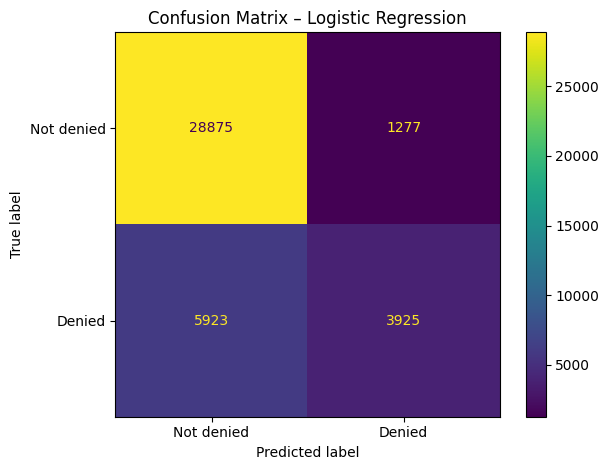

,Predicted not denied,Predicted denied
Actual not denied,29259,893
Actual denied,5002,4846


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_confusion_random_forest.csv | 94 bytes | 2 rows x 2 prediction columns (plus exported index labels)
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_confusion_random_forest.png | 37,041 bytes | 973 x 744 pixels


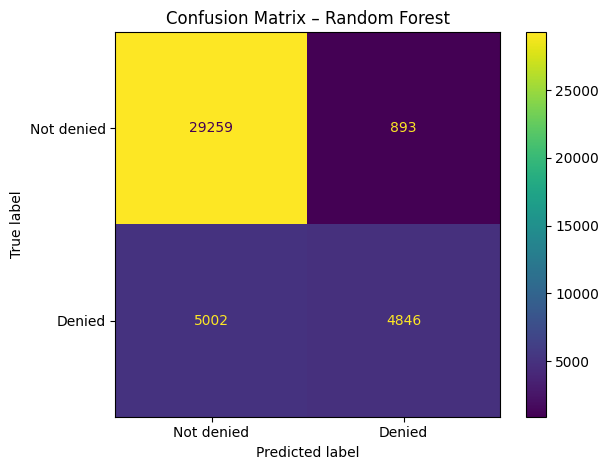

In [23]:
# Step 1: Save and plot each model's confusion matrix
confusion_matrices = {
    "logistic_regression": evaluation_results["Logistic Regression"][1],
    "random_forest": evaluation_results["Random Forest"][1]
}
for name, matrix in confusion_matrices.items():
    matrix_df = pd.DataFrame(
        matrix, index=["Actual not denied", "Actual denied"],
        columns=["Predicted not denied", "Predicted denied"]
    )
    matrix_path = OUTPUT_DIR / f"{TASK_CODE}_confusion_{name}.csv"
    matrix_df.to_csv(matrix_path)
    display(matrix_df)
    print(f"Saved: {matrix_path} | {matrix_path.stat().st_size:,} bytes | "
          f"{matrix_df.shape[0]} rows x {matrix_df.shape[1]} prediction columns "
          "(plus exported index labels)")

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=["Not denied", "Denied"]
    )
    display_plot.plot(values_format="d")
    plt.title(f"Confusion Matrix – {name.replace('_', ' ').title()}")
    plt.tight_layout()
    figure_path = OUTPUT_DIR / f"{TASK_CODE}_confusion_{name}.png"
    plt.savefig(figure_path, dpi=160, bbox_inches="tight")
    image_height, image_width = plt.imread(figure_path).shape[:2]
    print(f"Saved: {figure_path} | {figure_path.stat().st_size:,} bytes | "
          f"{image_width} x {image_height} pixels")
    plt.show()
    plt.close()

### P9.3. Interpret Logistic Regression features

**Input:** Fitted Logistic Regression pipeline, source predictor lists, and transformed feature names.  
**Process:** Map features using the explicit `num__` / `cat__` transformer prefixes and full predictor boundaries, including optional numeric missingness indicators. Validate the mapping against known collision cases and all model features. Extract coefficients and odds ratios.  
**Output:** Validated `lr_interpretation` table with one source predictor per encoded feature.

**[CHANGE: Step 3]** Replace substring matching, which incorrectly mapped `debt_to_income_ratio` to `income`. **[ADD: Step 3]** Fail loudly on unrecognized transformed names; no source predictor is guessed. Coefficients are model associations, not causal effects.

In [24]:
# Step 1: Map transformed feature names using exact transformer boundaries

def map_source_predictor(feature_name):
    """Map sklearn numeric, missing-indicator, and one-hot names to source columns."""
    name = str(feature_name)
    if name.startswith("num__"):
        source = name.removeprefix("num__").removeprefix("missingindicator_")
        if source in NUMERIC_FEATURES:
            return source
    elif name.startswith("cat__"):
        encoded = name.removeprefix("cat__")
        matches = [col for col in CATEGORICAL_FEATURES
                   if encoded.startswith(f"{col}_")]
        if len(matches) == 1:
            return matches[0]
    raise ValueError(f"Unrecognized transformed feature: {name}")

# Step 2: Validate numeric, categorical, and missing-indicator mappings
assert map_source_predictor("num__income") == "income"
assert map_source_predictor("cat__debt_to_income_ratio_>60") == "debt_to_income_ratio"
assert map_source_predictor("num__missingindicator_income") == "income"

print("Feature mapping validation: PASSED")
# Step 3: Build and validate Logistic Regression interpretation
lr_preprocessor = lr_model.named_steps["preprocessor"]
lr_names = lr_preprocessor.get_feature_names_out()
lr_coefficients = lr_model.named_steps["classifier"].coef_[0]
assert len(lr_names) == len(lr_coefficients)
lr_interpretation = pd.DataFrame({
    "encoded_feature": lr_names,
    "source_predictor": [map_source_predictor(x) for x in lr_names],
    "coefficient": lr_coefficients,
    "odds_ratio": np.exp(lr_coefficients)
}).sort_values("coefficient", key=np.abs, ascending=False)
assert lr_interpretation["source_predictor"].isin(PREDICTOR_COLUMNS).all()
print(f"Validated Logistic Regression feature mapping: {len(lr_names):,} features")
display(lr_interpretation.head(20))

Feature mapping validation: PASSED
Validated Logistic Regression feature mapping: 40 features


,encoded_feature,source_predictor,coefficient,odds_ratio
23,cat__debt_to_income_ratio_>60,debt_to_income_ratio,3.769360,43.352328
2,num__combined_loan_to_value_ratio,combined_loan_to_value_ratio,2.524737,12.487609
29,cat__loan_purpose_1,loan_purpose,-1.213988,0.297011
21,cat__debt_to_income_ratio_50-60,debt_to_income_ratio,1.038269,2.824324
27,cat__loan_type_3,loan_type,-0.823244,0.439005
39,cat__occupancy_type_3,occupancy_type,-0.577840,0.561109
13,cat__debt_to_income_ratio_42,debt_to_income_ratio,-0.560329,0.571021
11,cat__debt_to_income_ratio_40,debt_to_income_ratio,-0.497984,0.607755
36,cat__lien_status_2,lien_status,-0.491823,0.611510
7,cat__debt_to_income_ratio_36,debt_to_income_ratio,-0.486565,0.614734


### P9.4. Extract Random Forest importance and summarize

**Input:** Fitted Random Forest pipeline, transformed feature names, and the validated P9.3 mapping helper.  
**Process:** Map each encoded feature to exactly one source predictor and aggregate impurity-based importances. Check that the feature array aligns with the classifier and that aggregation preserves total importance.  
**Output:** Validated `rf_interpretation` and `rf_grouped_importance` tables.

**[ADD: Step 3]** Verify that no transformed feature is unmapped and that grouped importance sums to the feature-level total. Impurity-based importance is descriptive and may favor high-cardinality predictors.

In [25]:
# Step 1: Extract and validate encoded Random Forest features
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_names = rf_preprocessor.get_feature_names_out()
rf_values = rf_model.named_steps["classifier"].feature_importances_
assert len(rf_names) == len(rf_values)
rf_interpretation = pd.DataFrame({
    "encoded_feature": rf_names,
    "source_predictor": [map_source_predictor(x) for x in rf_names],
    "importance": rf_values
}).sort_values("importance", ascending=False)
assert rf_interpretation["source_predictor"].isin(PREDICTOR_COLUMNS).all()

# Step 2: Aggregate by source predictor and verify importance preservation
rf_grouped_importance = (
    rf_interpretation.groupby("source_predictor", as_index=False)["importance"]
    .sum().sort_values("importance", ascending=False)
)
assert np.isclose(rf_grouped_importance["importance"].sum(),
                  rf_interpretation["importance"].sum(), atol=1e-10)
assert np.isclose(rf_interpretation["importance"].sum(), 1.0, atol=1e-6)
print(f"Validated Random Forest feature mapping: {len(rf_names):,} features")
display(rf_grouped_importance)
print("Caution: impurity-based importance can favor high-cardinality predictors.")

Validated Random Forest feature mapping: 40 features


,source_predictor,importance
1,debt_to_income_ratio,0.509022
0,combined_loan_to_value_ratio,0.128402
5,loan_purpose,0.110522
2,income,0.098748
4,loan_amount,0.074696
6,loan_type,0.038101
3,lien_status,0.030106
7,occupancy_type,0.010403


Caution: impurity-based importance can favor high-cardinality predictors.


### P9.5. Save metrics, predictions, and interpretation outputs

**Input:** Evaluation metrics, predictions, source IDs, and interpretation tables.  
**Process:** Export all final tables using the task-code prefix. Print each saved file's path, size, and dimensions.  
**Output:** Reproducible CSV and Parquet artifacts under `output/`.

In [26]:
# Step 1: Assemble evaluation predictions
prediction_output = pd.DataFrame({
    "source_row_id": test_source_ids,
    "actual_is_denied": y_test.to_numpy()
})
for name, result in evaluation_results.items():
    key = name.lower().replace(" ", "_")
    prediction_output[f"{key}_probability"] = result[2]
    prediction_output[f"{key}_prediction"] = result[3]

# Step 2: Save tables and report file metadata
export_tables = {
    "metrics": metrics_table,
    "predictor_audit": predictor_audit,
    "missingness_audit": missing_audit,
    "logistic_coefficients": lr_interpretation,
    "random_forest_importance": rf_interpretation,
    "random_forest_grouped_importance": rf_grouped_importance,
    "test_predictions": prediction_output
}
for name, table in export_tables.items():
    path = OUTPUT_DIR / f"{TASK_CODE}_{name}.csv"
    table.to_csv(path, index=False)
    print(f"{path} | {path.stat().st_size:,} bytes | {table.shape[0]:,} rows x {table.shape[1]} columns")

D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_metrics.csv | 434 bytes | 2 rows x 9 columns
D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_predictor_audit.csv | 726 bytes | 8 rows x 6 columns
D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_missingness_audit.csv | 265 bytes | 8 rows x 3 columns
D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_logistic_coefficients.csv | 3,394 bytes | 40 rows x 4 columns
D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_random_forest_importance.csv | 2,654 bytes | 40 rows x 3 columns
D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_random_forest_grouped_importance.csv | 316 bytes | 8 rows x 2 columns
D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B17 - Predictive\output\B17_test_predictions.csv | 2,167,222 b

## Final interpretation and reproducibility checklist

Before writing the report, verify that:

- The sample contains the Human-approved number of rows and was stratified by original `action_taken` values `1`, `2`, and `3`, without replacement.
- `is_denied` is `1` only for `action_taken = 3`; actions `1` and `2` map to `0`.
- The eight proposal-core predictors are used, and denial reasons are excluded.
- Both models use the same train/evaluation observations; preprocessing is fitted only to training data.
- ROC-AUC, trapezoidal PR-AUC, supplementary Average Precision, precision, recall, F1-score, and confusion matrices are correctly distinguished.
- Predictive associations are not described as causal effects or proof of discrimination.
- P5 numerical coercion counts, P6 convergence status, and P9.3–P9.4 feature-mapping checks are reviewed in the **current** execution.
- All exported artifacts appear under `output/`, with the `B17_` prefix and printed metadata.

## Decisions and outstanding validation

**[Verified: Human decision]** The sampling design (200,000 rows, seed 42), baseline split, imputation, threshold, and original model defaults were previously approved by the Human. The notebook uses the same approved target and predictors.

**[Human decision required]** The Step 2 change to Logistic Regression (`solver="lbfgs"`, `max_iter=3000`) addresses a previously observed convergence warning. The new setting still needs confirmation after the current run; record its rationale and effect on metrics in `origin/decisions.md` if accepted.

**[Verified: static review, Step 5]** Notebook JSON structure, presence of an immediately preceding English Input/Process/Output Markdown cell for each code cell, and Python syntax of standard code cells were checked. The P0 setup is a documented exception to the approximately 40-line guideline because it centralizes configuration. This review did **not** establish end-to-end correctness or data-dependent outcomes.

**[Not verified: execution]** The complete notebook was **not** rerun in this review environment: the input Parquet file is located on the user's Windows drive and `pyarrow` is not installed in the review environment. Cached outputs/execution counts from older runs are historical only; changed cells must be rerun. Confirm **Kernel → Restart & Run All** in the `B17 - Predictive/` folder, and examine the P5 audit, P6 `Converged: True`, P9.4 importance validation, and all exported-file metadata before reporting results.

**[CHANGE: Step 5]** Correct outdated notebook execution/approval language without changing the sampling, training, evaluation, or interpretation code.
